# TA-03: Data-Driven Monte Carlo Simulation
## Simulasi Risiko Penurunan Harga Saham BCA (BBCA.JK) dalam 30 Hari ke Depan

**Pertanyaan bisnis:** berapa probabilitas harga saham BBCA turun lebih dari 10% dalam 30 hari ke depan?

**Alur notebook (Load Data Kaggle sampai Hasil Simulasi):**

**Langkah 1 - Eksplorasi Data**
1. Import library
2. Load data
3. Cek struktur data
4. Rapikan nama kolom & tipe data
5. Data cleaning (null, duplikat, nilai tidak valid, hari tanpa transaksi)
6. Return harian & outlier ekstrem
7. Ringkasan cleaning
8. Ekstraksi parameter (mean, std) + histogram
9. Simpan data bersih

**Langkah 2 - Membangun Simulasi Monte Carlo**
10. Pengaturan simulasi
11. Menjalankan simulasi (30 hari x ribuan jalur)
12. Visualisasi jalur harga

**Langkah 3 - Analisis Risiko & Kesimpulan**
13. Hitung probabilitas
14. Histogram hasil dengan garis batas (threshold)
15. Analisis tambahan & kesimpulan

---
# LANGKAH 1: Eksplorasi Data
### 1. Import Library

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 150)

### 2. Load Data
Dataset **BBCA.JK.csv** (dari Kaggle) dibaca langsung dari lokasi filenya. Ubah `CSV_PATH` di bawah jika file berada di folder lain.

In [4]:
# Lokasi file dataset (ubah sesuai tempat file kamu disimpan)
CSV_PATH = "BBCA.JK.csv"      # file berada di folder yang sama dengan notebook

# Contoh lokasi lain (hapus tanda # pada salah satunya):
# CSV_PATH = r"C:\Users\Lenovo\Documents\data\BBCA.JK.csv"        # path lengkap di Windows
# CSV_PATH = "data/BBCA.JK.csv"                                   # di dalam subfolder "data"
CSV_PATH = "/content/BBCA.JK.csv"                               # Google Colab (panel Files)

df_raw = pd.read_csv(CSV_PATH)

print("Ukuran data awal:", df_raw.shape)
df_raw.head()

Ukuran data awal: (1896, 8)


,Date,open,high,low,close,adjclose,volume,ingested_at_utc
0,2019-01-01,5200.0,5200.0,5200.0,5200.0,4223.863281,0,2026-10-22 05:33:58.957440+00:00
1,2019-01-02,5200.0,5245.0,5200.0,5240.0,4256.353516,35956000,2026-10-22 05:33:58.957440+00:00
2,2019-01-03,5200.0,5220.0,5115.0,5180.0,4207.616699,72358000,2026-10-22 05:33:58.957440+00:00
3,2019-01-04,5175.0,5205.0,5125.0,5205.0,4227.924316,51465000,2026-10-22 05:33:58.957440+00:00
4,2019-01-07,5265.0,5325.0,5245.0,5245.0,4260.415527,73438000,2026-10-22 05:33:58.957440+00:00


### 3. Cek Struktur Data

In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1896 entries, 0 to 1895
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             1896 non-null   object 
 1   open             1896 non-null   float64
 2   high             1896 non-null   float64
 3   low              1896 non-null   float64
 4   close            1896 non-null   float64
 5   adjclose         1896 non-null   float64
 6   volume           1896 non-null   int64  
 7   ingested_at_utc  1896 non-null   object 
dtypes: float64(5), int64(1), object(2)
memory usage: 118.6+ KB


In [6]:
df_raw.describe().round(2)

,open,high,low,close,adjclose,volume
count,1896.00,1896.00,1896.00,1896.00,1896.00,1.896000e+03
mean,7579.56,7650.66,7507.73,7576.76,6705.59,1.013997e+08
std,1500.38,1505.50,1497.33,1501.91,1512.85,9.404899e+07
min,4450.00,4800.00,4325.00,4430.00,3642.79,0.000000e+00
25%,6250.00,6300.00,6188.75,6257.50,5344.34,5.789220e+07
50%,7475.00,7550.00,7400.00,7487.50,6573.23,8.006225e+07
75%,8875.00,8925.00,8775.00,8850.00,8009.48,1.133300e+08
max,10900.00,10950.00,10775.00,10950.00,9989.80,1.432993e+09


### 4. Rapikan Nama Kolom & Tipe Data
- Nama kolom dibuat seragam (huruf awal besar).
- Kolom `ingested_at_utc` dibuang karena hanya catatan waktu pengambilan data, tidak dipakai.
- Kolom `Date` diubah ke tipe tanggal dan data diurutkan dari yang terlama.

In [7]:
df = df_raw.copy()

# buang kolom yang tidak dipakai
df = df.drop(columns=["ingested_at_utc"], errors="ignore")

# seragamkan nama kolom
df.columns = [c.strip().title() for c in df.columns]
df = df.rename(columns={"Adjclose": "Adj Close"})

# ubah tipe data tanggal & urutkan
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("Kolom:", list(df.columns))
print("Periode:", df["Date"].min().date(), "s/d", df["Date"].max().date())
df.head()

Kolom: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
Periode: 2019-01-01 s/d 2026-10-21


,Date,Open,High,Low,Close,Adj Close,Volume
0,2019-01-01,5200.0,5200.0,5200.0,5200.0,4223.863281,0
1,2019-01-02,5200.0,5245.0,5200.0,5240.0,4256.353516,35956000
2,2019-01-03,5200.0,5220.0,5115.0,5180.0,4207.616699,72358000
3,2019-01-04,5175.0,5205.0,5125.0,5205.0,4227.924316,51465000
4,2019-01-07,5265.0,5325.0,5245.0,5245.0,4260.415527,73438000


### 5. Data Cleaning
Kita simpan jumlah baris di setiap langkah supaya mudah dilaporkan.

In [8]:
log = {"Data awal": len(df)}

**5.1 Cek nilai kosong (null)**

In [9]:
print("Jumlah null per kolom:")
print(df.isnull().sum())

df = df.dropna().reset_index(drop=True)
log["Setelah hapus null"] = len(df)
print("\nBaris setelah hapus null:", len(df))

Jumlah null per kolom:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

Baris setelah hapus null: 1896


**5.2 Cek data duplikat**

In [10]:
print("Baris duplikat penuh :", df.duplicated().sum())
print("Tanggal duplikat     :", df["Date"].duplicated().sum())

df = df.drop_duplicates(subset="Date").reset_index(drop=True)
log["Setelah hapus duplikat"] = len(df)

Baris duplikat penuh : 0
Tanggal duplikat     : 0


**5.3 Cek nilai tidak valid**

Harga harus lebih dari 0, dan harga tertinggi (High) tidak boleh lebih kecil dari harga terendah (Low).

In [11]:
harga = ["Open", "High", "Low", "Close", "Adj Close"]

print("Harga <= 0 :", (df[harga] <= 0).sum().sum())
print("High < Low :", (df["High"] < df["Low"]).sum())

valid = (df[harga] > 0).all(axis=1) & (df["High"] >= df["Low"])
df = df[valid].reset_index(drop=True)
log["Setelah hapus nilai tidak valid"] = len(df)

Harga <= 0 : 0
High < Low : 0


**5.4 Hapus hari tanpa transaksi (Volume = 0)**

Pada hari libur bursa, data tetap tercatat tetapi volumenya 0 dan harga open = high = low = close (harga hanya "copy" dari hari sebelumnya). Hari seperti ini bukan pergerakan harga yang sebenarnya, jadi dibuang.

In [12]:
tanpa_transaksi = df[df["Volume"] == 0]
print("Jumlah hari tanpa transaksi:", len(tanpa_transaksi))
display(tanpa_transaksi[["Date", "Open", "High", "Low", "Close", "Volume"]].head(10))

df = df[df["Volume"] > 0].reset_index(drop=True)
log["Setelah hapus hari tanpa transaksi"] = len(df)

Jumlah hari tanpa transaksi: 15


,Date,Open,High,Low,Close,Volume
0,2019-01-01,5200.0,5200.0,5200.0,5200.0,0
25,2019-02-05,5500.0,5500.0,5500.0,5500.0,0
47,2019-03-07,5490.0,5490.0,5490.0,5490.0,0
66,2019-04-03,5500.0,5500.0,5500.0,5500.0,0
76,2019-04-17,5495.0,5495.0,5495.0,5495.0,0
78,2019-04-19,5625.0,5625.0,5625.0,5625.0,0
86,2019-05-01,5750.0,5750.0,5750.0,5750.0,0
107,2019-05-30,5740.0,5740.0,5740.0,5740.0,0
109,2019-06-03,5820.0,5820.0,5820.0,5820.0,0
110,2019-06-04,5820.0,5820.0,5820.0,5820.0,0


### 6. Return Harian & Outlier Ekstrem

Parameter simulasi diambil dari **return harian**:

$$return_t = \frac{Close_t - Close_{t-1}}{Close_{t-1}}$$

Outlier dideteksi dengan **metode IQR** pada return. Batas yang dipakai adalah **3 x IQR** (batas "ekstrem", lebih longgar dari 1,5 x IQR) supaya hanya lonjakan yang benar-benar jauh dari biasanya yang dibuang.

Catatan: outlier dibuang dari **data return** saja. Data harga tetap utuh, sehingga harga terakhir (harga awal simulasi) tidak berubah.

In [13]:
PRICE_COL = "Close"      # bisa diganti "Adj Close" jika ingin memperhitungkan dividen
IQR_FACTOR = 3           # 3 = outlier ekstrem, 1.5 = outlier biasa

df["Return"] = df[PRICE_COL].pct_change()

# baris pertama tidak punya return (tidak ada hari sebelumnya), jadi wajar kosong
returns = df.dropna(subset=["Return"]).copy()

q1, q3 = returns["Return"].quantile([0.25, 0.75])
iqr = q3 - q1
batas_bawah = q1 - IQR_FACTOR * iqr
batas_atas  = q3 + IQR_FACTOR * iqr

print(f"Q1 = {q1:.5f} | Q3 = {q3:.5f} | IQR = {iqr:.5f}")
print(f"Batas bawah = {batas_bawah:.4f} ({batas_bawah*100:.2f}%)")
print(f"Batas atas  = {batas_atas:.4f} ({batas_atas*100:.2f}%)")

Q1 = -0.00848 | Q3 = 0.00822 | IQR = 0.01670
Batas bawah = -0.0586 (-5.86%)
Batas atas  = 0.0583 (5.83%)


In [14]:
is_outlier = (returns["Return"] < batas_bawah) | (returns["Return"] > batas_atas)
outliers = returns[is_outlier]

print("Jumlah outlier ekstrem:", len(outliers), f"({len(outliers)/len(returns)*100:.2f}% dari data)")
print("\n5 return terbesar yang terdeteksi:")
display(outliers.reindex(outliers["Return"].abs().sort_values(ascending=False).index)
        [["Date", "Close", "Volume", "Return"]].head(5))

Jumlah outlier ekstrem: 23 (1.22% dari data)

5 return terbesar yang terdeteksi:


,Date,Close,Volume,Return
302,2020-03-26,5280.0,331633000,0.173333
1877,2026-10-16,5175.0,1241098200,-0.148148
1788,2026-06-10,5650.0,747366000,0.097087
1512,2025-04-08,7775.0,533073600,-0.085294
296,2020-03-17,5120.0,212200000,-0.079137


> **Catatan penting:** beberapa outlier ini adalah kejadian pasar yang nyata (misalnya guncangan pasar Maret 2020), bukan kesalahan data. Membuangnya membuat estimasi risiko sedikit lebih kecil. Ini adalah keputusan analisis dan sebaiknya dijelaskan di laporan. Jika ingin tetap menyertakannya, ubah `HAPUS_OUTLIER` di bawah menjadi `False`.

In [15]:
HAPUS_OUTLIER = True

returns_clean = returns[~is_outlier].copy() if HAPUS_OUTLIER else returns.copy()
log["Data return (setelah hitung return)"] = len(returns)
log["Data return (setelah hapus outlier)"] = len(returns_clean)

**Visualisasi sebelum dan sesudah outlier dibuang**

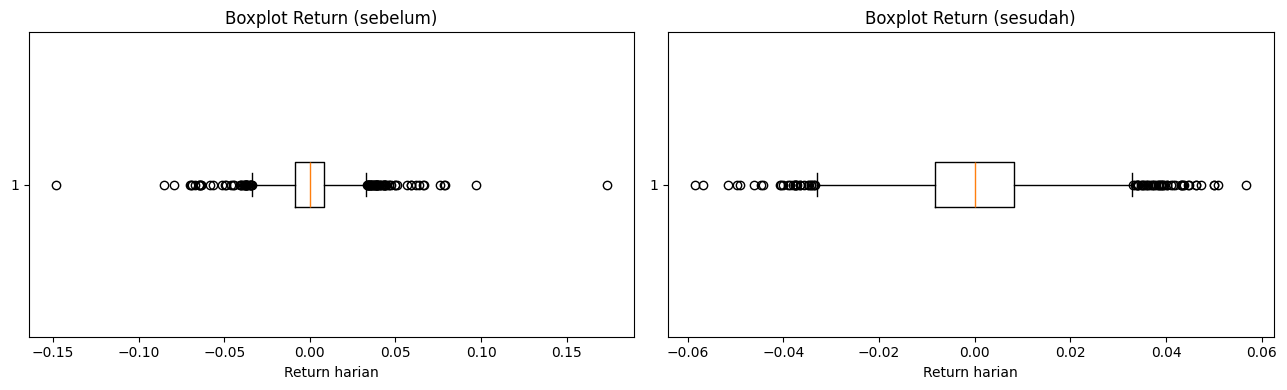

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].boxplot(returns["Return"], vert=False, showfliers=True)
ax[0].set_title("Boxplot Return (sebelum)")
ax[0].set_xlabel("Return harian")

ax[1].boxplot(returns_clean["Return"], vert=False, showfliers=True)
ax[1].set_title("Boxplot Return (sesudah)")
ax[1].set_xlabel("Return harian")

plt.tight_layout()
plt.show()

### 7. Ringkasan Cleaning

In [17]:
ringkasan = pd.DataFrame({"Tahap": list(log.keys()), "Jumlah baris": list(log.values())})
ringkasan["Berkurang"] = ringkasan["Jumlah baris"].diff().fillna(0).astype(int)
ringkasan

,Tahap,Jumlah baris,Berkurang
0,Data awal,1896,0
1,Setelah hapus null,1896,0
2,Setelah hapus duplikat,1896,0
3,Setelah hapus nilai tidak valid,1896,0
4,Setelah hapus hari tanpa transaksi,1881,-15
5,Data return (setelah hitung return),1880,-1
6,Data return (setelah hapus outlier),1857,-23


### 8. Ekstraksi Parameter Simulasi

Dari return yang sudah bersih, kita hitung **rata-rata (mu)** dan **standar deviasi (sigma)**. Harga penutupan terakhir menjadi **harga awal (S0)** simulasi.

In [18]:
mu = returns_clean["Return"].mean()
sigma = returns_clean["Return"].std()
S0 = df[PRICE_COL].iloc[-1]
tanggal_akhir = df["Date"].iloc[-1].date()

print(f"Jumlah data return : {len(returns_clean)}")
print(f"Mean (mu)          : {mu:.6f}  ({mu*100:.4f}% per hari)")
print(f"Std Dev (sigma)    : {sigma:.6f}  ({sigma*100:.4f}% per hari)")
print(f"Harga awal (S0)    : Rp {S0:,.0f}  (per {tanggal_akhir})")
print(f"Skewness           : {stats.skew(returns_clean['Return']):.4f}")
print(f"Kurtosis (excess)  : {stats.kurtosis(returns_clean['Return']):.4f}")

Jumlah data return : 1857
Mean (mu)          : 0.000166  (0.0166% per hari)
Std Dev (sigma)    : 0.014538  (1.4538% per hari)
Harga awal (S0)    : Rp 5,275  (per 2026-10-21)
Skewness           : 0.1853
Kurtosis (excess)  : 1.1675


**Histogram return harian dan kurva distribusi normal**

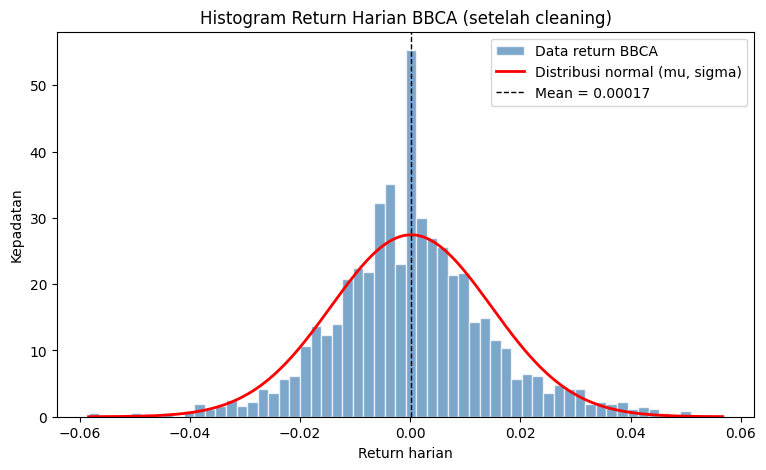

In [19]:
plt.figure(figsize=(9, 5))
plt.hist(returns_clean["Return"], bins=60, density=True, alpha=0.7,
         color="steelblue", edgecolor="white", label="Data return BBCA")

x = np.linspace(returns_clean["Return"].min(), returns_clean["Return"].max(), 300)
plt.plot(x, stats.norm.pdf(x, mu, sigma), "r-", lw=2, label="Distribusi normal (mu, sigma)")

plt.axvline(mu, color="black", ls="--", lw=1, label=f"Mean = {mu:.5f}")
plt.title("Histogram Return Harian BBCA (setelah cleaning)")
plt.xlabel("Return harian")
plt.ylabel("Kepadatan")
plt.legend()
plt.show()

**Interpretasi singkat (isi sesuai hasilmu):** bentuk histogram return mendekati lonceng (distribusi normal) dengan pusat di sekitar 0, sehingga `np.random.normal(mu, sigma)` cukup layak dipakai untuk simulasi. Nilai kurtosis yang positif menunjukkan ekor distribusi lebih "tebal" dari normal, artinya kejadian ekstrem sedikit lebih sering daripada yang diperkirakan distribusi normal. Ini dicatat sebagai keterbatasan model.

**Grafik harga penutupan (untuk melihat tren keseluruhan)**

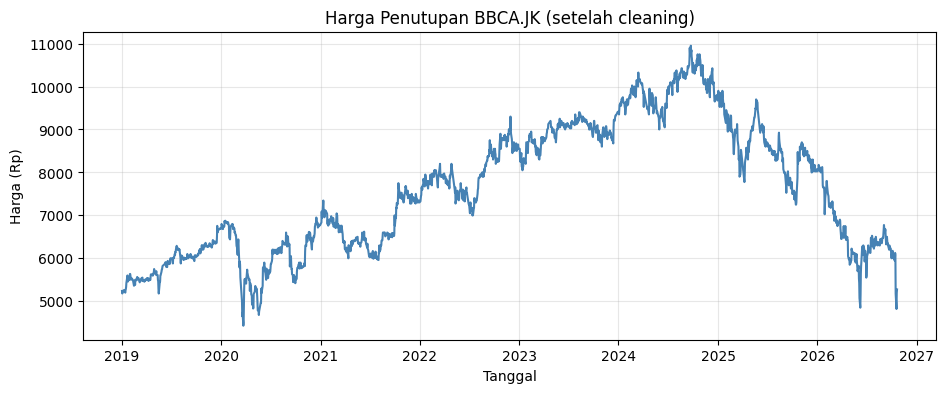

In [20]:
plt.figure(figsize=(11, 4))
plt.plot(df["Date"], df[PRICE_COL], color="steelblue")
plt.title("Harga Penutupan BBCA.JK (setelah cleaning)")
plt.xlabel("Tanggal")
plt.ylabel("Harga (Rp)")
plt.grid(alpha=0.3)
plt.show()

### 9. Simpan Data Bersih

In [21]:
df.to_csv("BBCA_clean.csv", index=False)
returns_clean[["Date", "Return"]].to_csv("BBCA_returns_clean.csv", index=False)
print("Tersimpan: BBCA_clean.csv dan BBCA_returns_clean.csv")

# di Colab, hapus tanda # di bawah jika ingin mengunduh file hasilnya
# from google.colab import files
# files.download("BBCA_clean.csv"); files.download("BBCA_returns_clean.csv")

Tersimpan: BBCA_clean.csv dan BBCA_returns_clean.csv


---
# LANGKAH 2: Membangun Simulasi Monte Carlo

Ide dasarnya: kita "memainkan" 30 hari ke depan sebanyak ribuan kali. Setiap hari, return diambil secara acak dari distribusi normal dengan parameter **mu** dan **sigma** hasil Langkah 1. Harga dihitung dengan rumus:

$$price_t = price_{t-1} \times (1 + return\_acak)$$

### 10. Pengaturan Simulasi

In [22]:
np.random.seed(301240010)   # seed = NIM, supaya hasil konsisten tiap dijalankan

N_SIM = 10000               # jumlah skenario/jalur (minimal 5.000)
N_DAYS = 30                 # horizon simulasi: 30 hari perdagangan ke depan
BATAS_TURUN = 0.10          # risiko: harga turun lebih dari 10%

threshold = S0 * (1 - BATAS_TURUN)

print(f"Harga awal (S0)       : Rp {S0:,.0f}")
print(f"Jumlah skenario       : {N_SIM:,}")
print(f"Horizon               : {N_DAYS} hari")
print(f"Batas risiko (turun {BATAS_TURUN*100:.0f}%) : Rp {threshold:,.0f}")

Harga awal (S0)       : Rp 5,275
Jumlah skenario       : 10,000
Horizon               : 30 hari
Batas risiko (turun 10%) : Rp 4,748


### 11. Menjalankan Simulasi
Semua return acak dibangkitkan sekaligus dalam satu matriks berukuran (jumlah skenario x jumlah hari), lalu harga dihitung dengan `cumprod` (perkalian berantai), yaitu sama dengan menerapkan `price_t = price_t-1 * (1 + return)` hari demi hari.

In [23]:
# matriks return acak: tiap baris = 1 skenario, tiap kolom = 1 hari
return_acak = np.random.normal(mu, sigma, size=(N_SIM, N_DAYS))

# jalur harga: kolom 0 = harga awal (S0), kolom 1..30 = hari ke-1 sampai ke-30
jalur = np.empty((N_SIM, N_DAYS + 1))
jalur[:, 0] = S0
jalur[:, 1:] = S0 * np.cumprod(1 + return_acak, axis=1)

harga_akhir = jalur[:, -1]      # harga pada hari ke-30 di setiap skenario

print("Ukuran matriks jalur:", jalur.shape)
print(f"Contoh 5 harga akhir : {np.round(harga_akhir[:5], 0)}")

Ukuran matriks jalur: (10000, 31)
Contoh 5 harga akhir : [5287. 5388. 4951. 4981. 5953.]


### 12. Visualisasi Jalur Harga

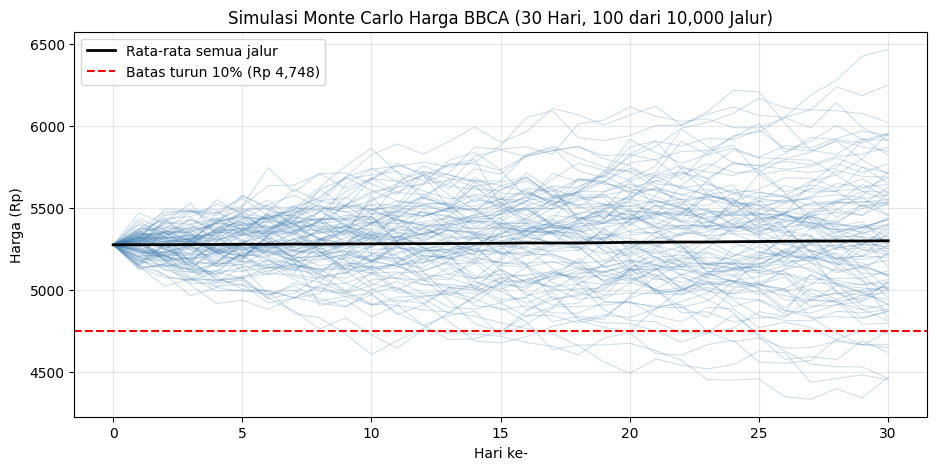

In [24]:
plt.figure(figsize=(11, 5))
hari = np.arange(N_DAYS + 1)

# tampilkan 100 jalur saja supaya grafik tidak terlalu padat
plt.plot(hari, jalur[:100].T, color="steelblue", alpha=0.25, lw=0.8)
plt.plot(hari, jalur.mean(axis=0), color="black", lw=2, label="Rata-rata semua jalur")
plt.axhline(threshold, color="red", ls="--", lw=1.5, label=f"Batas turun 10% (Rp {threshold:,.0f})")

plt.title(f"Simulasi Monte Carlo Harga BBCA ({N_DAYS} Hari, 100 dari {N_SIM:,} Jalur)")
plt.xlabel("Hari ke-")
plt.ylabel("Harga (Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
# LANGKAH 3: Analisis Risiko & Kesimpulan

### 13. Hitung Probabilitas

$$P(Event) = \frac{\text{Jumlah skenario yang memenuhi kondisi}}{\text{Total skenario}}$$

Kondisi yang dicari: harga hari ke-30 lebih rendah dari batas (turun lebih dari 10% dari harga awal).

In [25]:
kondisi = harga_akhir < threshold
jumlah_kejadian = kondisi.sum()
probabilitas = jumlah_kejadian / N_SIM

print(f"Total skenario                    : {N_SIM:,}")
print(f"Skenario harga turun > {BATAS_TURUN*100:.0f}%        : {jumlah_kejadian:,}")
print(f"Probabilitas turun > {BATAS_TURUN*100:.0f}% (30 hari) : {probabilitas:.4f} = {probabilitas*100:.2f}%")

Total skenario                    : 10,000
Skenario harga turun > 10%        : 894
Probabilitas turun > 10% (30 hari) : 0.0894 = 8.94%


### 14. Histogram Hasil Simulasi dengan Garis Batas (Threshold)

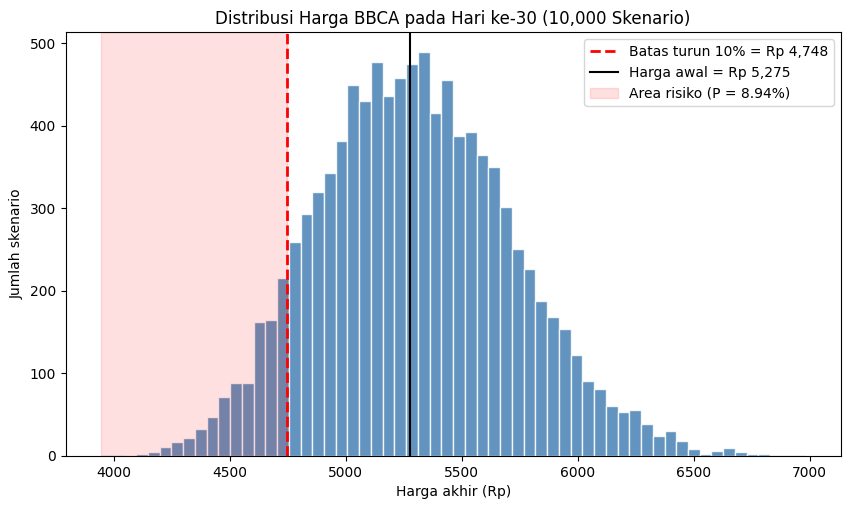

In [26]:
plt.figure(figsize=(10, 5.5))
plt.hist(harga_akhir, bins=60, color="steelblue", edgecolor="white", alpha=0.85)

plt.axvline(threshold, color="red", ls="--", lw=2,
            label=f"Batas turun 10% = Rp {threshold:,.0f}")
plt.axvline(S0, color="black", ls="-", lw=1.5, label=f"Harga awal = Rp {S0:,.0f}")

# warnai area risiko (di bawah batas)
plt.axvspan(harga_akhir.min(), threshold, color="red", alpha=0.12,
            label=f"Area risiko (P = {probabilitas*100:.2f}%)")

plt.title(f"Distribusi Harga BBCA pada Hari ke-{N_DAYS} ({N_SIM:,} Skenario)")
plt.xlabel("Harga akhir (Rp)")
plt.ylabel("Jumlah skenario")
plt.legend()
plt.show()

### 15. Analisis Tambahan & Kesimpulan
Selain batas 10%, kita lihat juga ringkasan hasil simulasi dan probabilitas pada beberapa batas lain.

In [27]:
perubahan = (harga_akhir - S0) / S0      # perubahan harga dalam 30 hari

ringkasan_sim = pd.DataFrame({
    "Statistik": ["Rata-rata harga akhir", "Median harga akhir", "Harga akhir terendah",
                  "Harga akhir tertinggi", "Persentil ke-5 (skenario buruk)"],
    "Nilai (Rp)": [harga_akhir.mean(), np.median(harga_akhir), harga_akhir.min(),
                   harga_akhir.max(), np.percentile(harga_akhir, 5)]
}).round(0)
display(ringkasan_sim)

batas_lain = pd.DataFrame({
    "Penurunan lebih dari": ["5%", "10%", "15%", "20%"],
    "Probabilitas": [(perubahan < -b).mean() for b in (0.05, 0.10, 0.15, 0.20)]
})
batas_lain["Probabilitas (%)"] = (batas_lain["Probabilitas"] * 100).round(2)
display(batas_lain)

# probabilitas harga SEMPAT menyentuh batas di tengah jalan (bukan hanya di hari ke-30)
prob_menyentuh = (jalur.min(axis=1) < threshold).mean()
print(f"Probabilitas harga sempat turun > 10% kapan saja dalam {N_DAYS} hari: {prob_menyentuh*100:.2f}%")

,Statistik,Nilai (Rp)
0,Rata-rata harga akhir,5299.0
1,Median harga akhir,5285.0
2,Harga akhir terendah,3944.0
3,Harga akhir tertinggi,6982.0
4,Persentil ke-5 (skenario buruk),4638.0


,Penurunan lebih dari,Probabilitas,Probabilitas (%)
0,5%,0.2564,25.64
1,10%,0.0894,8.94
2,15%,0.0178,1.78
3,20%,0.0014,0.14


Probabilitas harga sempat turun > 10% kapan saja dalam 30 hari: 15.33%


In [28]:
print("=" * 60)
print("KESIMPULAN")
print("=" * 60)
print(f"Saham         : BBCA.JK (Bank Central Asia)")
print(f"Harga awal    : Rp {S0:,.0f} (per {tanggal_akhir})")
print(f"Parameter     : mu = {mu*100:.4f}% | sigma = {sigma*100:.4f}% per hari")
print(f"Simulasi      : {N_SIM:,} skenario x {N_DAYS} hari")
print(f"Probabilitas harga turun > 10% dalam {N_DAYS} hari: {probabilitas*100:.2f}%")
print("=" * 60)

KESIMPULAN
Saham         : BBCA.JK (Bank Central Asia)
Harga awal    : Rp 5,275 (per 2026-10-21)
Parameter     : mu = 0.0166% | sigma = 1.4538% per hari
Simulasi      : 10,000 skenario x 30 hari
Probabilitas harga turun > 10% dalam 30 hari: 8.94%


**Interpretasi (sesuaikan kalimatnya dengan hasilmu saat dijalankan):**
- Hasil di atas berarti dari 10.000 kemungkinan pergerakan harga, sekitar sekian persen berakhir turun lebih dari 10% pada hari ke-30. Itu estimasi risiko penurunan harga BBCA dalam 30 hari.
- Semakin besar batas penurunan (15%, 20%), probabilitasnya semakin kecil.

**Keterbatasan model (untuk laporan):**
- Return diasumsikan berdistribusi normal dan saling bebas antar hari. Pada data nyata, ekor distribusi biasanya lebih tebal sehingga kejadian ekstrem bisa lebih sering dari perkiraan simulasi.
- Parameter mu dan sigma dianggap tetap selama 30 hari, padahal volatilitas pasar bisa berubah.
- Outlier ekstrem dibuang pada tahap cleaning (atur `HAPUS_OUTLIER`), sehingga risiko bisa sedikit terlihat lebih kecil dari kenyataan.
- Hasil simulasi bukan prediksi pasti dan bukan saran investasi.